# Exploring trade-offs in stellarator design with the ConStellaration dataset

This notebook looks at what trade-offs show up between **confinement**, **stability** and **geometry** in stellarator plasma shapes, using Proxima Fusion's open ConStellaration dataset (~160,000 shapes after removing incomplete entries).

The metrics I focus on:
**QI residual**: how close a shape is to being quasi-isodynamic. Lower means better particle confinement.
**Aspect ratio**: major radius divided by minor radius. Higher ratio means a thinner, larger ring.
**Number of field periods (N_fp)**: how many times the shape repeats around the torus.
**Vacuum well**: a measure of MHD stability. Positive means stable.

*Valdemar Westphal Johansen, Engineering Physics, Technical University of Denmark (DTU).*

**How this notebook was made:** I'm a first-semester student and haven't had any plasma physics courses yet. I made this notebook together with an AI assistant (Claude). The AI explained the physics concepts, suggested which analyses to run, wrote most of the code and helped me phrase the text. My part was setting up the environment, running and debugging the code, deciding what to look into next, and checking that the results made sense to me.

I understand the main findings, but not the stellarator theory behind them in depth. The point of this notebook is to show my interest in Proxima's work and that I can find my way around an unfamiliar scientific dataset, not to claim expertise in plasma physics.

In [1]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt

In [2]:
cols = [
    "metrics.aspect_ratio",
    "metrics.max_elongation",
    "metrics.edge_rotational_transform_over_n_field_periods",
    "metrics.qi",
    "metrics.vacuum_well",
    "boundary.n_field_periods",
    "boundary.r_cos",
    "boundary.z_sin",
]

df = pl.read_parquet("constellaration_subset.parquet", columns=cols)
print(df.shape)
print(df.select(cols[:6]).describe())

# First run: download from Hugging Face and save a local copy
# df = pl.read_parquet("hf://datasets/proxima-fusion/constellaration/data/*.parquet", columns=cols)
# df = df.drop_nulls("metrics.qi")
# df.write_parquet("constellaration_subset.parquet")


(158685, 8)
shape: (9, 7)
┌────────────┬──────────────┬──────────────┬──────────────┬────────────┬─────────────┬─────────────┐
│ statistic  ┆ metrics.aspe ┆ metrics.max_ ┆ metrics.edge ┆ metrics.qi ┆ metrics.vac ┆ boundary.n_ │
│ ---        ┆ ct_ratio     ┆ elongation   ┆ _rotational_ ┆ ---        ┆ uum_well    ┆ field_perio │
│ str        ┆ ---          ┆ ---          ┆ transf…      ┆ f64        ┆ ---         ┆ ds          │
│            ┆ f64          ┆ f64          ┆ ---          ┆            ┆ f64         ┆ ---         │
│            ┆              ┆              ┆ f64          ┆            ┆             ┆ f64         │
╞════════════╪══════════════╪══════════════╪══════════════╪════════════╪═════════════╪═════════════╡
│ count      ┆ 158685.0     ┆ 158685.0     ┆ 158685.0     ┆ 158685.0   ┆ 158685.0    ┆ 158685.0    │
│ null_count ┆ 0.0          ┆ 0.0          ┆ 0.0          ┆ 0.0        ┆ 0.0         ┆ 0.0         │
│ mean       ┆ 8.618404     ┆ 4.805673     ┆ 0.231896     ┆ 0.023

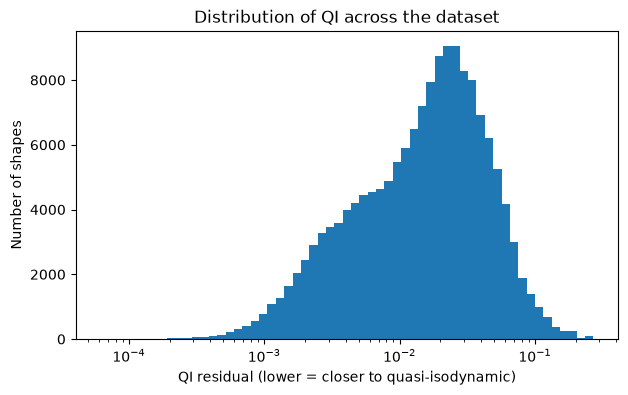

In [3]:
qi = df["metrics.qi"].to_numpy()

bins = np.logspace(np.log10(qi.min()), np.log10(qi.max()), 60)

plt.figure(figsize=(7, 4))
plt.hist(qi, bins=bins)
plt.xscale("log")
plt.xlabel("QI residual (lower = closer to quasi-isodynamic)")
plt.ylabel("Number of shapes")
plt.title("Distribution of QI across the dataset")
plt.show()

Most shapes have a QI residual between roughly $10^{-3}$ and $10^{-1}$, with the peak around $10^{-2}$. The number of shapes drops off sharply below $10^{-3}$: shapes that come close to being quasi-isodynamic are rare, even in a dataset generated specifically to explore good designs.

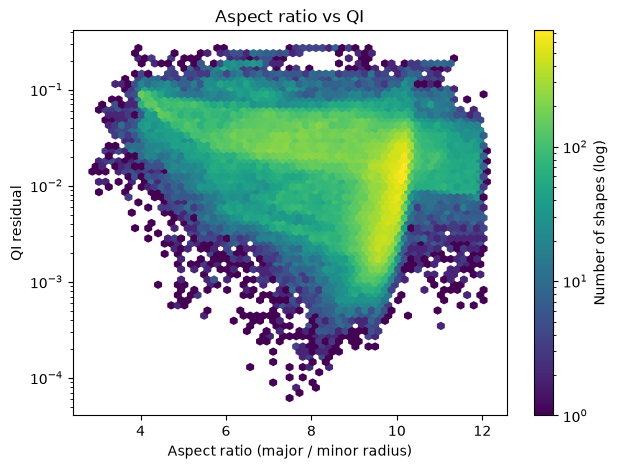

In [4]:
ar = df["metrics.aspect_ratio"].to_numpy()

plt.figure(figsize=(7, 5))
plt.hexbin(ar, qi, yscale="log", gridsize=60, bins="log", mincnt=1)
plt.colorbar(label="Number of shapes (log)")
plt.xlabel("Aspect ratio (major / minor radius)")
plt.ylabel("QI residual")
plt.title("Aspect ratio vs QI")
plt.show()

Two things stand out:

**Compact shapes have worse confinement.** Below an aspect ratio of about 7, the best achievable QI gets noticeably worse. Compact stellarators are harder to make quasi-isodynamic.
**The best shapes sit between aspect ratio of about 7 and 9.** The lowest QI in the whole dataset (≈ $6 \times 10^{-5}$) has an aspect ratio of 7.4.

The bright vertical band at aspect ratio ≈ 10 is probably not physics. It is likely where the optimizer that generated the dataset was told to aim, so many shapes ended up there.

In [5]:
summary = (
    df.group_by("boundary.n_field_periods")
      .agg(
          pl.len().alias("count"),
          pl.col("metrics.qi").median().alias("median_qi"),
          pl.col("metrics.qi").quantile(0.05).alias("best_5pct_qi"),
      )
      .sort("boundary.n_field_periods")
)
print(summary)


shape: (5, 4)
┌──────────────────────────┬───────┬───────────┬──────────────┐
│ boundary.n_field_periods ┆ count ┆ median_qi ┆ best_5pct_qi │
│ ---                      ┆ ---   ┆ ---       ┆ ---          │
│ i64                      ┆ u32   ┆ f64       ┆ f64          │
╞══════════════════════════╪═══════╪═══════════╪══════════════╡
│ 1                        ┆ 14607 ┆ 0.0109    ┆ 0.001661     │
│ 2                        ┆ 19945 ┆ 0.008546  ┆ 0.001008     │
│ 3                        ┆ 68191 ┆ 0.020362  ┆ 0.002347     │
│ 4                        ┆ 27798 ┆ 0.014475  ┆ 0.001693     │
│ 5                        ┆ 28144 ┆ 0.017852  ┆ 0.002036     │
└──────────────────────────┴───────┴───────────┴──────────────┘


Shapes with **2 field periods** have both the lowest median QI and the lowest QI among their best 5%. Looking only at confinement, N_fp = 2 performs best in this dataset.

N_fp = 3 is by far the most common but has the worst median, so having more samples doesn't mean better shapes. Stellaris (N_fp = 4) and Wendelstein 7-X (N_fp = 5) were chosen with many other engineering factors in mind (coils, stability, size), so this ranking only reflects confinement.

In [6]:
best = df.sort("metrics.qi").row(0, named=True)

r_cos = np.array(best["boundary.r_cos"])
z_sin = np.array(best["boundary.z_sin"])
nfp = best["boundary.n_field_periods"]

print("QI:", best["metrics.qi"], " aspect ratio:", best["metrics.aspect_ratio"], " N_fp:", nfp)
print("coefficient array shape:", r_cos.shape)
print("Vacuum well:", best["metrics.vacuum_well"])

def surface_of(row, theta, phi):
    r_cos = np.array(row["boundary.r_cos"])
    z_sin = np.array(row["boundary.z_sin"])
    nfp = row["boundary.n_field_periods"]
    R = np.zeros_like(theta, dtype=float)
    Z = np.zeros_like(theta, dtype=float)
    n_m, n_cols = r_cos.shape
    ntor = (n_cols - 1) // 2
    for m in range(n_m):
        for j in range(n_cols):
            n = j - ntor
            angle = m * theta - n * nfp * phi
            R += r_cos[m, j] * np.cos(angle)
            Z += z_sin[m, j] * np.sin(angle)
    return R, Z

QI: 6.146820028575814e-05  aspect ratio: 7.428607515108144  N_fp: 2
coefficient array shape: (5, 9)
Vacuum well: -0.020001891226805422


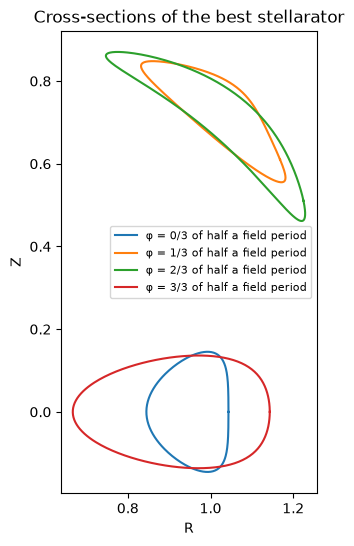

In [7]:
theta = np.linspace(0, 2 * np.pi, 300)
half_period = np.pi / nfp

plt.figure(figsize=(6, 6))
for k in range(4):
    phi = k * half_period / 3
    R, Z = surface_of(best, theta, np.full_like(theta, phi))
    plt.plot(R, Z, label=f"φ = {k}/3 of half a field period")

plt.gca().set_aspect("equal")
plt.xlabel("R")
plt.ylabel("Z")
plt.title("Cross-sections of the best stellarator")
plt.legend(fontsize=8)
plt.show()

Cross-sections of the shape with the lowest QI in the dataset, taken at four angles across half a field period.

At φ = 0 the cross-section is mirror-symmetric around Z = 0, which is what stellarator symmetry predicts, so the Fourier reconstruction is working. The later slices move up to around Z ≈ 0.5-0.9: the magnetic axis isn't flat but winds up and down as it goes around the torus.

In [8]:
similar = df.filter(
    (pl.col("boundary.n_field_periods") == 4)
    & (pl.col("metrics.aspect_ratio").is_between(9, 11))
    & (pl.col("metrics.vacuum_well") > 0)
)
print(similar.height)

47


In [9]:
best_similar = similar.sort("metrics.qi").row(0, named=True)
print("QI:", best_similar["metrics.qi"])
print("Aspect ratio:", best_similar["metrics.aspect_ratio"])
print("Vacuum well:", best_similar["metrics.vacuum_well"])

QI: 0.0015202172769479773
Aspect ratio: 9.330857783246213
Vacuum well: 0.003800067131380738


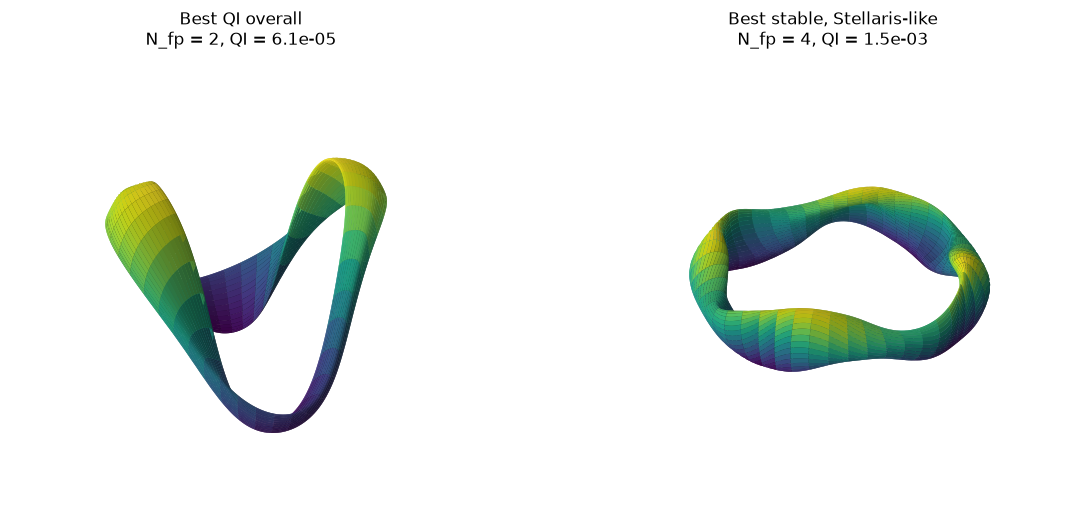

In [10]:
theta_grid, phi_grid = np.meshgrid(np.linspace(0, 2*np.pi, 80), np.linspace(0, 2*np.pi, 300))

fig = plt.figure(figsize=(14, 6))
for i, (row, title) in enumerate([(best, "Best QI overall"), (best_similar, "Best stable, Stellaris-like")]):
    R, Z = surface_of(row, theta_grid, phi_grid)
    X, Y = R * np.cos(phi_grid), R * np.sin(phi_grid)
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    ax.plot_surface(X, Y, Z, facecolors=plt.cm.viridis((Z - Z.min()) / np.ptp(Z)), linewidth=0)
    ax.set_box_aspect((np.ptp(X), np.ptp(Y), np.ptp(Z)))
    ax.set_axis_off()
    ax.set_title(f"{title}\nN_fp = {row['boundary.n_field_periods']}, QI = {row['metrics.qi']:.1e}")
plt.show()

**Left:** the shape with the lowest QI in the whole dataset (N_fp = 2), with no other requirements.
**Right:** the best shape that resembles Proxima's Stellaris design: N_fp = 4, aspect ratio between 9 and 11, and a positive vacuum well (MHD stable).

Only **47 of the 158,685 shapes** (0.03%) meet all three of those requirements. The best of them has a QI of $1.5 \times 10^{-3}$, about **25 times worse** than the unconstrained best shape.

## Conclusion

Good quasi-isodynamic confinement is rare: very few shapes have a QI residual below $10^{-3}$.
Compact shapes (aspect ratio < 7) struggle to reach low QI. The best results cluster at aspect ratio 7.5–9.
On confinement alone, N_fp = 2 does best in this dataset.
Adding stability is expensive: requiring a positive vacuum well together with Stellaris-like geometry leaves only 47 shapes, and the best of those has 25× worse QI.

This shows why stellarator design is hard. Confinement, stability and geometry pull in different directions, and designs like Stellaris have to balance all of them at once instead of optimizing just one.